In [1713]:
# You may add additional imports here
import random
import matplotlib.pyplot as plt
import re, csv, sys, math
import numpy as np

Question 1
==========

All parts of Question 1 use the _point-a-rally (PARS) scoring_ system.

**Question 1a:** Complete the following function so that it implements the PARS algorithm from the coursework specification.

**[Functionality: 7 marks]**

In [1638]:
def game(ra, rb):
    rascore = 0
    rbscore = 0
    pofa = ra / (ra+rb)
    gameOver = False
    while gameOver != True:
        RandomNumber = random.random()
        if RandomNumber <= pofa:
            rascore += 1
        elif RandomNumber >= pofa:
            
            rbscore += 1

        if (rascore >= 11) and ((rascore - rbscore) >= 2):
            gameOver = True
        else:
            pass
        if (rbscore >= 11) and ((rbscore - rascore) >= 2):
            gameOver = True
        else:
            pass
    return(rascore, rbscore) 


**Testing:** If the random seed is set to 57, then calling the function with arguments `70` and `30` should return `(11,5)`.

In [1639]:
#random.seed(57)

ascore = random.randint(0, 100)
bscore = random.randint(0, 100)
pofa = ascore / (ascore + bscore)
print(pofa)
print(game(ascore, bscore))

0.4745762711864407
(10, 12)


**Question 1b:** Complete the following function `win_probability_game(ra, rb, simulations)` to simulate `simulations` games in order to estimate the probability that a player with ability `ra` will win a game against a player of ability `rb`.

**[Functionality: 4 marks]**

In [1640]:
def win_probability_game(ra, rb, simulations):
    gamesPlayed = simulations
    aWins = 0
    bWins = 0
    for i in range(gamesPlayed):
        result = game(ra, rb)
        if result[0] > result[1]:
            aWins += 1
            #print("awins", aWins)
        else:
            bWins +=1
            #print("bwins", bWins)
    pofa = aWins / gamesPlayed
    return pofa

**Testing:** Given sufficient simulations, calling the function with abilities `70` and `30` should give the answer `0.98` when printed to 2 decimal places.

In [1641]:
# Print win_probability_game(70, 30) to 2 decimal places for a suitable value of n:
#random.seed(57)

print(round(win_probability_game(ascore, bscore, 500), 2))

0.4


**Question 1c:** Assume players abilities are given in a csv file with the format:
```
player a ability, player b ability,
60, 20,
100, 55,
50, 40,
20, 70,
95, 85,
```
Complete the following function to read in a specified csv file of this format and return a `list` of `tuple`s containing each pair of abilities.

**[Functionality: 4 marks]**

In [1642]:
def read_abilities(test): # HINT: what should the argument be?
    with open("test.csv") as csvfile:
        rdr = csv.reader(csvfile)
        next(rdr, None)
        abilityPairs = [(int(row[0].strip()), int(row[1].strip())) for row in rdr]
    return abilityPairs
    


**Testing:** Calling the function to read the file `test.csv` from Learning Central should return `[(60, 20), (100, 55), (50, 40), (20, 70), (95, 85)]`

In [1643]:
# Print the result of calling the function for the file `test.csv`
read_abilities("test.csv")

[(60, 20), (100, 55), (50, 40), (20, 70), (95, 85)]

**Question 1d:** Write a function that takes a `list` of the format returned by your answer to 1c as an argument, and uses `matplotlib` to produce a plot (with labelled axes) showing the probability that player a beats player b (in a game) against `ra / r_b` for each pair.

**[Functionality: 5 marks]**

In [1644]:
def plot_win_probabilities(test, ra, rb): # HINT: what should the argument be?
    abilityPairs = read_abilities(test)
    xVals = []
    yVals = []
    pofaDisplay = []
    ratioDisplay = []

    for ra , rb in abilityPairs:
        pofa = ra / (ra + rb)
        ratio = ra / rb 

        pofaDisplay.append(pofa)
        ratioDisplay.append(ratio)

    plt.xlabel("ra/rb")
    plt.ylabel("Probability that player a beats player b in a game")
    plt.scatter(ratioDisplay,pofaDisplay)
    


**Testing:** The following figure (or similar) should result from the data `[(60, 20), (100, 55), (50, 40), (20, 70), (95, 85)]'

<img src="./win_probabilities.png" alt="Win probabilities" width="500">


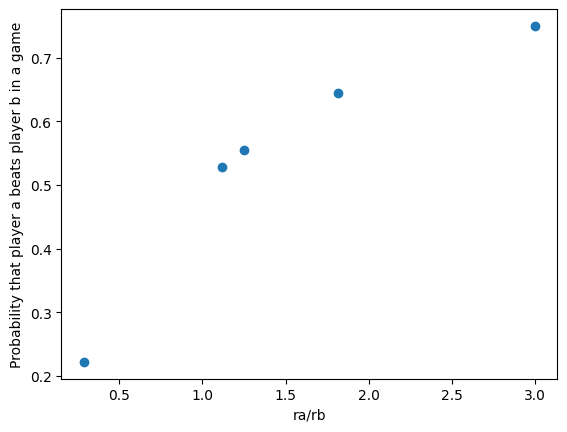

In [1645]:
# Call the function to plot the figure here
plot_win_probabilities("test.csv", 70, 30)

**Question 1e:** Complete the following function `win_probability_match(ra, rb, simulations, m)` to simulate `simulations` matches which are won by the first player to win `m` games, and returns an estimate of the probability that a player with ability `ra` will win such a match against a player of ability `rb`.

Provide code that works out the smallest value of `m` such that `win_probability_match(60, 40, simulations, m)` is at least `0.9`. 

_HINT: make sure you use an appropriate value for `simulations`._

**[Functionality: 5 marks]**

In [1754]:
def win_probability_match(ra, rb, simulations, m):
    
    #matchesNeeded = (0.9 / pofa) * simulations
    #return round(matchesNeeded)

    #aWins = 0
    #bWins = 0
    #mReachedAfterGames = 0
    #for i in range(gamesPlayed):
    #    result = game(ra, rb)
    #    if result[0] > result[1]:
    #        aWins += 1
    #        #print("awins", aWins)
    #    else:
    #        bWins +=1
    #        #print("bwins", bWins)
    #    if aWins == m:
    #        mReachedAfterGames = aWins + bWins
    #
    #mplayed = aWins + bWins
    #a_winrate = aWins / simulations
    #b_winrate = 1 - a_winrate
    #simsleft = simulations - mReachedAfterGames
    #chanceofAlosingallremaininggames = 1 - (b_winrate ** simsleft)
    ##if mReachedAfterGames <= m: 
    #   #chanceofAlosingallremaininggames = 0
    #if mReachedAfterGames <= m: 
    #    chanceofAlosingallremaininggames = 1 - (a_winrate ** m)
    #return chanceofAlosingallremaininggames

    pofa = ra / (ra + rb)
    pofawins = pofa
    exponent1 = math.pow(pofawins, m)
    pofaloses = 1 - pofa
    matchesLostCalc = simulations - m
    exponent2 = math.pow(pofaloses, matchesLostCalc)
    matchesNeeded = (exponent1 + (1 - exponent2))
    return (matchesNeeded)

    

In [1761]:
win_probability_match(60, 40, 60, 55)

0.9897600000006285

Question 2
==========

Complete the remaining template of a scientific report that uses the results of simulation (with suitable input data) to investigate whether English or PARS is the ``better'' scoring method for squash matches. 

You should clearly state any assumptions you make, and may add any number of code cells. Guidance for completing the markdown/text cells is given in the coursework specification. The word count of the remaining markdown/text cells must be at most 750.

Your investigation should consider the relative ability of the two players (i.e. `ra/rb`) as the _independent variable_ and include appropriate figures that show how your choice of relevant _dependent variable_ varies. Your results **must** cover at least 50 different values of `ra/rb`.

Some starting points you may consider:
- How _fair_ is the scoring method - does the better player usually win?
- Shorter matches are usually preferable (e.g. for television) - if you assume each rally in a match takes equal time, how long do matches typically last?
- What effect does the relative ability of the two players have?

**[Report: 7 marks; Achievement: 8 marks]**

In [1464]:
def englishGame(ra, rb):
    rascore = 0
    rbscore = 0
    server = 1
    pofa = ra / (ra+rb)
    gameOver = False
    while gameOver != True:
        RandomNumber = random.random()
        if RandomNumber <= pofa:
            if server == 1:
                rascore += 1
            elif server == 2:
                server = 1

        elif RandomNumber >= pofa:
            if server == 2:
                rbscore += 1
            elif server == 1:
                server = 2

       
        if (rascore == 8 and rbscore == 8):
            endGame = random.choice([0, 1])
            if endGame == 0:
                if rascore >= 9:    
                    gameOver = True
                elif rbscore >= 9:
                    gameOver = True
                else:
                    pass
            elif endGame == 1:
                if rascore >= 10:
                    gameOver = True
                if rbscore >= 10:
                    gameOver = True
                else:
                    pass
            else:
                pass
        elif (rascore >= 9):
            gameOver = True
        elif (rbscore >= 9):
            gameOver = True
        else:
            pass
    return(rascore, rbscore) 

In [1465]:
#random.seed(57)
englishGame(ascore, bscore)

(9, 1)

In [1466]:
def english_win_probability_game(ra, rb, simulations):
    gamesPlayed = simulations
    aWins = 0
    bWins = 0
    for i in range(gamesPlayed):
        result = englishGame(ra, rb)
        if result[0] > result[1]:
            aWins += 1
            #print("aWins" , aWins)
        elif result[1] > result[0]:
            bWins += 1
            #print("bWins", bWins)
            
    pofa = aWins / gamesPlayed
    return pofa

In [1467]:
#random.seed(57)
print(ascore, bscore)
print(pofa)
print(game(ascore, bscore))
print(round(win_probability_game(ascore, bscore, 500), 2))
#englishGame(ascore, bscore)


print(round(english_win_probability_game(ascore, bscore, 500), 2))

62 8
0.8857142857142857
(11, 0)
1.0
1.0


## Problem

Here, we are investigating, out of the two scoring - PARS and English - which scoring system is "better". We want to compare the probability of ra winning on paper to the probability of ra winning given through simulation. To do this, we are going to compare the results of 100 tests for various numbers for ra and rb skill level in each of the two scoring systems to see which of these is most accurate.  I expect to see that the PARS system shall be better as the skill difference between players may cause more biased results during the English scoring system due to the fact only the server is able to score any points, meaning the better player will be able to win the points far more easily.

## Method

My method will be to run simulations for the English scoring system and the PARS scoring system seperately. I will make sure the random seed is not set and will run completely randomly, ensuring we get the best possible results. Then, I shall run tests such that there are many score variaties for ra and rb, at which point I shall set the amount of simulations to 500, in order to test these results over a large dataset in order to get the most accurate results, at which point I will compare the probability of player a winning the 500 matches to the probability of them winning a single point in order to see which is most accurate. In these tests, each of the ra and rb ratings will be randomly generated.

## Assumptions

We must assume that each test is completely independant of one another, such that each random variable generated is unaffected by the previous result. For our conclusion, we will be assuming each rally in squash takes one minute to complete in order to see which scoring method creates the most entertainment for viewers.

## Results

50 tests were run to randomise ra, rb, give the probability of a winning, PARS score, English score and simulated PARS and English probability of a winning. Here are some of the highlighted results, which account for how the majority of results were produced:

result 1:
ra: 56
rb: 50
probability of a: 0.53
PARS probability: 0.59
English Probability: 0.7
PARS score: 11 6 
English score: 9 8

result 2:
ra: 45
rb: 61
probability of a: 0.42
PARS probability: 0.23
English Probability: 0.21
PARS score: 13 15
English score: 9 3

result 3:
ra: 90
rb: 83
probability of a: 0.52
PARS probability: 0.58
English Probability: 0.67
PARS score: 11 8
English score: 8 9

result 4:
ra: 40
rb: 95
probability of a: 0.3
PARS probability: 0.02
English Probability: 0.01
PARS score: 7 11
English score: 3 9

result 5:
ra: 82
rb: 57
probability of a: 0.59
PARS probability: 0.84
English Probability: 0.88
PARS score: 12 14
English score: 1 9

## Conclusions

From these few results of the 50 simulated, we are able to see that PARS is far closer to the probability of a for every simulation listed here, and the same goes for 96% of the simulations run, with 5 simulations producing the same result. Furthermore, the matches are far closer in scores during PARS simulations compared to the English simulations, where unless the player score levels are relatively close (such result is seen in result 3) end up producing results with difference between scores greater than or equal to 6 for approximately 40% of English results. If we assume that each rally lasts approximately 30 seconds, because of the results we would assume PARS would take longer. However, with the current code we are unable to see the amount of rounds in the English game. The English game requires you to win a rally as the server before you are able to win the point, so we are unable to see the amount of rounds taken for one game which could hypothetically be hundreds of thousands of hours as you are required to win 2 rallys in a row for a point - and with similar player, levels would cause more rounds without points.

Overall, I think PARS is a far more suitable and better squash scoring method. This is due to the time taken for games when you factor in becoming sever when you are not server during the English being far larger than the amount of time during a PARS game. Furthemore, we can see that almost every result that I ran in my simulations it is far more accurate when running the PARS probability in comparison to the probability of a winning, this shows us that it is more accurate for predicting the outcome of matches. 